In [1]:
#import torch
import xarray as xr
import matplotlib.pyplot as plt
import warnings
import numpy as np
import pandas as pd
import math
import zarr
import warnings
from production_funcs import make_date_ranges,training_date_ranges,plotPMvsData,reach_back,frp_time_scale
#from torch_models import mlp_baseline
from pyproj import CRS, Transformer

In [3]:
path = "/home/exouser/fireAirqaulity/training_data/X_train.csv"

column_names = ['thing', 'thing2', 'thing3', 'thing4','thing5','frp','pm','futpm']

df = pd.read_csv(path, names=column_names, header=None)

Text(0, 0.5, 'pm25')

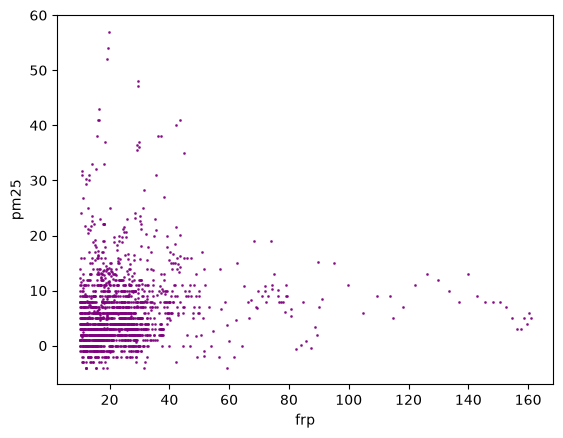

In [17]:
threshold = 10
plt.scatter(df[df['frp']>threshold]['frp'], df[df['frp']>threshold]['pm'], color="purple", marker="o", s=1, alpha=0.8)
plt.xlabel("frp")
plt.ylabel("pm25")

<Axes: >

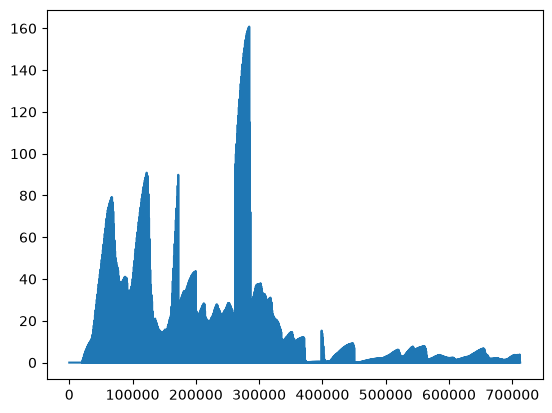

In [8]:
df['frp'].plot()

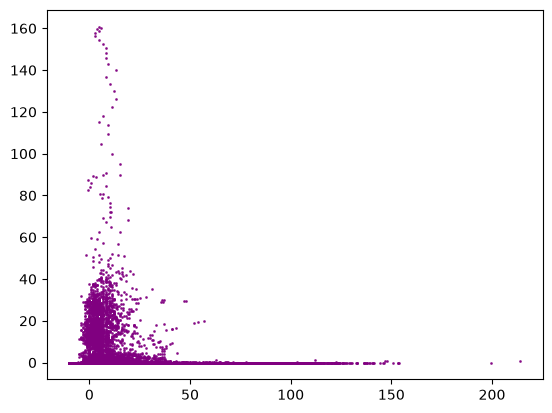

In [20]:
plt.scatter(df.iloc[:,5], df.iloc[:,6], color="purple", marker="o", s=1, alpha=0.8)


In [4]:
df[df['collective_frp']>0.5]['collective_frp'].mean()

np.float64(10.379109270334675)

<Axes: >

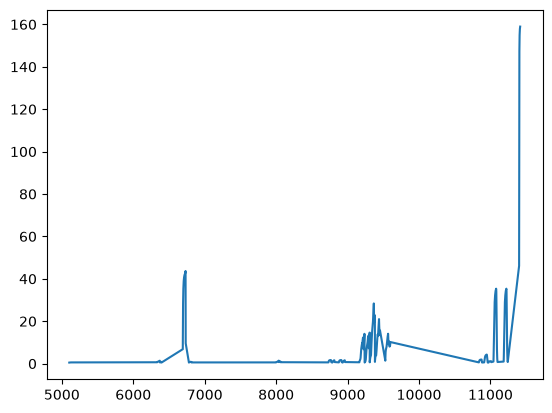

In [6]:
df[df['collective_frp']>.5]['collective_frp'].plot()

In [2]:
dates,_ = make_date_ranges(start_date='2025-01-07 1:00',end_date='2025-01-07 20:00')
print(dates)

Index(['2025-01-07 01:00', '2025-01-07 02:00', '2025-01-07 03:00',
       '2025-01-07 04:00', '2025-01-07 05:00', '2025-01-07 06:00',
       '2025-01-07 07:00', '2025-01-07 08:00', '2025-01-07 09:00',
       '2025-01-07 10:00', '2025-01-07 11:00', '2025-01-07 12:00',
       '2025-01-07 13:00', '2025-01-07 14:00', '2025-01-07 15:00',
       '2025-01-07 16:00', '2025-01-07 17:00', '2025-01-07 18:00',
       '2025-01-07 19:00', '2025-01-07 20:00'],
      dtype='str')


In [7]:
reach_back('2025-01-07 09:00',dates,6)

8
2


Index(['2025-01-07 03:00', '2025-01-07 04:00', '2025-01-07 05:00',
       '2025-01-07 06:00', '2025-01-07 07:00', '2025-01-07 08:00',
       '2025-01-07 09:00'],
      dtype='str')

In [2]:
data_x = np.loadtxt('training_data/X_train.csv', delimiter=',')
data_y = np.loadtxt('training_data/y_train.csv', delimiter=',')

In [13]:
corr_matrix = np.corrcoef(data_x[:,5], data_y)

# Extract the correlation coefficient
correlation_coefficient = corr_matrix[0, 1]
correlation_coefficient

np.float64(0.09494264533264543)

In [4]:
print(data_x.shape)
print(data_y.shape)

(43712, 7)
(43712,)


In [4]:
data_y

array([ 3. ,  7.8, 10.5, ...,  9.6, -4.1,  5.4], shape=(43712,))

add a mean into the input, the global mean or something
dont add xy coords as a input until the spacial component is needed
or mabye not, just try
or temporal stuff 

make it classification, is it higher then the long term mean value or not? or put it into bins

use f1 loss or precision recall, something like that

check when is the pm2.5 above the mean or a std deveation above the mean

documentation and making the code nicer 

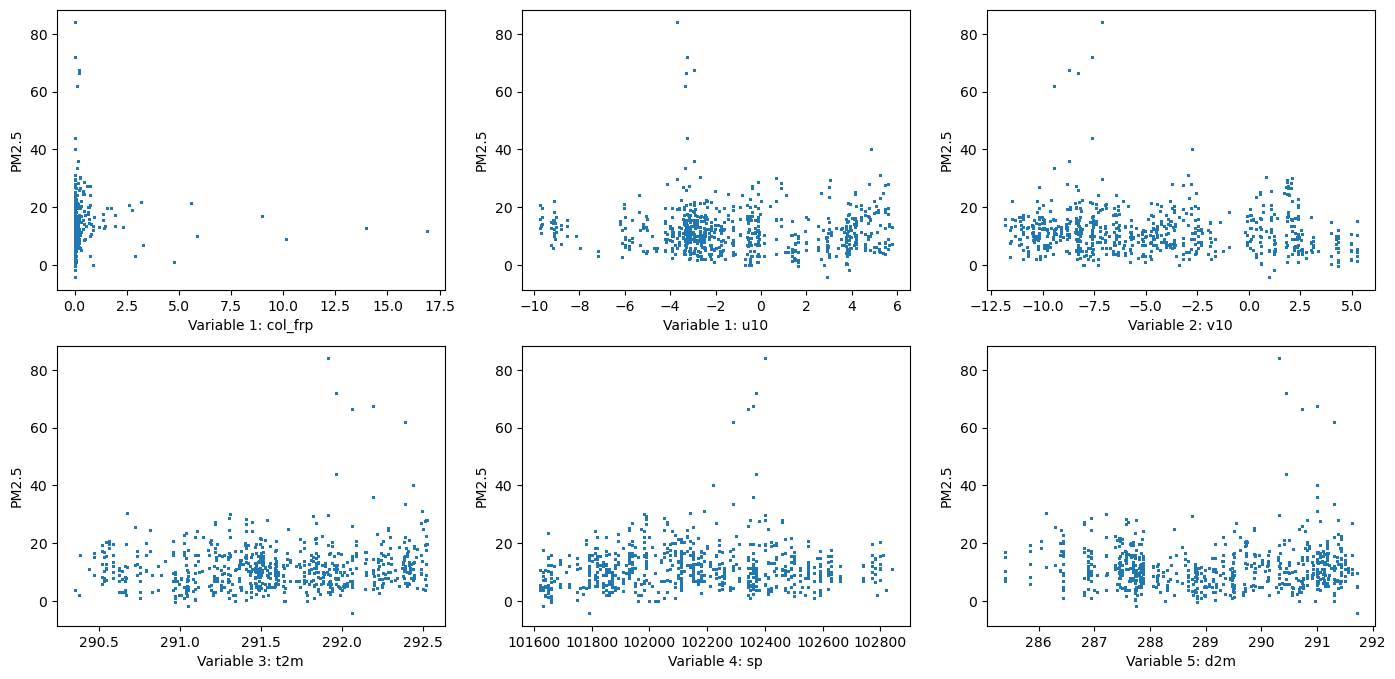

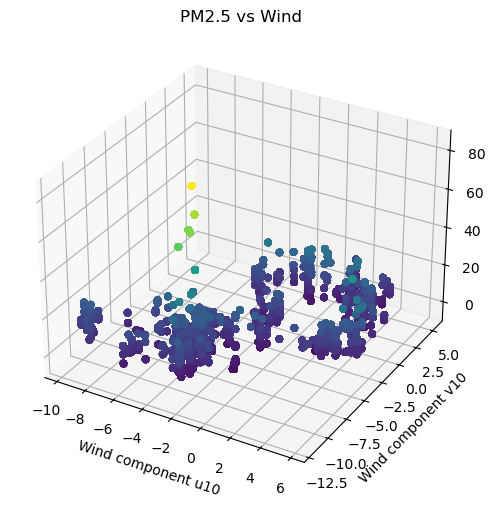

In [5]:
plotPMvsData(data_x,data_y)

In [9]:

class mlp_baseline_2(torch.nn.Module):
    def __init__(self,inputsize, depth, width):
        super().__init__()
        self.inp = torch.nn.Linear(inputsize, width)
        self.blocks = torch.nn.ModuleList([
            torch.nn.Sequential(
                torch.nn.Linear(width, width),
                torch.nn.LeakyReLU(),
            ) for _ in range(depth)
        ])
        self.out = torch.nn.Linear(width, 1)

    def forward(self, x):
        x = self.inp(x)
        for block in self.blocks:
            x = block(x)
        return self.out(x)

In [30]:
x_mean = data_x.mean(axis=0)
x_std = data_x.std(axis=0)
data_x_norm = (data_x - x_mean) / x_std
y_mean = data_y.mean(axis=0)
y_std = data_y.std(axis=0)
data_y_norm = (data_y - y_mean) / y_std

In [33]:
model = mlp_baseline_2(inputsize=7,depth=60,width=150)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
L = torch.nn.MSELoss()

In [34]:
n_epochs = 1
batch_size = 700
batch_counter = 0
epochs_loss = []
batch_loss = 0
batch_loss_list = []
for epoch in range(n_epochs):
    epoch_l = 0
    
    for x,y in zip(data_x_norm,data_y_norm): #_norm
        x_tensor = torch.tensor(x,dtype=torch.float32)
        y_tensor = torch.tensor(y,dtype=torch.float32)

                              
        y_pred = model(x_tensor)
        train_loss = L(y_tensor,y_pred[0])
        train_loss.backward() #accumulated gradients

        batch_loss += train_loss.item()
        print(f"Training loss for 1 datapoint: {train_loss.item()}")
        epoch_l += train_loss.item()

        if batch_counter == batch_size:
            batch_counter = 0
            optimizer.step()
            optimizer.zero_grad() # Clear gradients for this batch
            batch_loss_list.append(batch_loss/batch_size)
            print(f"Batch loss: {batch_loss/batch_size}")
            batch_loss = 0            
        else:
            batch_counter+=1
        
    epoch_l = epoch_l/len(data_x)
    epochs_loss.append(epoch_l)
    #print(f"Epoch: {epoch} Loss: {epoch_l}")
    


Training loss for 1 datapoint: 1.26239013671875
Training loss for 1 datapoint: 0.2872747480869293
Training loss for 1 datapoint: 0.042216137051582336
Training loss for 1 datapoint: 1.26239013671875
Training loss for 1 datapoint: 1.8724828958511353
Training loss for 1 datapoint: 0.4018423557281494
Training loss for 1 datapoint: 0.09204906970262527
Training loss for 1 datapoint: 0.0021463821176439524
Training loss for 1 datapoint: 0.4018423557281494
Training loss for 1 datapoint: 1.26239013671875
Training loss for 1 datapoint: 0.15138699114322662
Training loss for 1 datapoint: 0.0090809790417552
Training loss for 1 datapoint: 0.024492422118782997
Training loss for 1 datapoint: 0.4018423557281494
Training loss for 1 datapoint: 1.0022987127304077
Training loss for 1 datapoint: 1.26239013671875
Training loss for 1 datapoint: 0.22541013360023499
Training loss for 1 datapoint: 9.226042311638594e-05
Training loss for 1 datapoint: 0.26162976026535034
Training loss for 1 datapoint: 1.55245161056

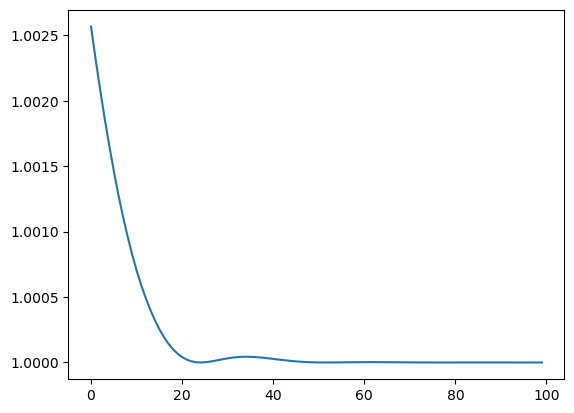

In [140]:
plt.plot(epochs_loss)

at first without epochs, the training was all over the place,

upon adding epochs the model actually had good loss behavor, however it was simply predicting the mean of the data, a sgin of underfiiting,
 
now i have increased the models capacity in hopes of improving it, however what happened was after about 54 epochs, the loss went up, ocsilated a bit until settling down, so i suspect i overfit the model now, i will attach a picture

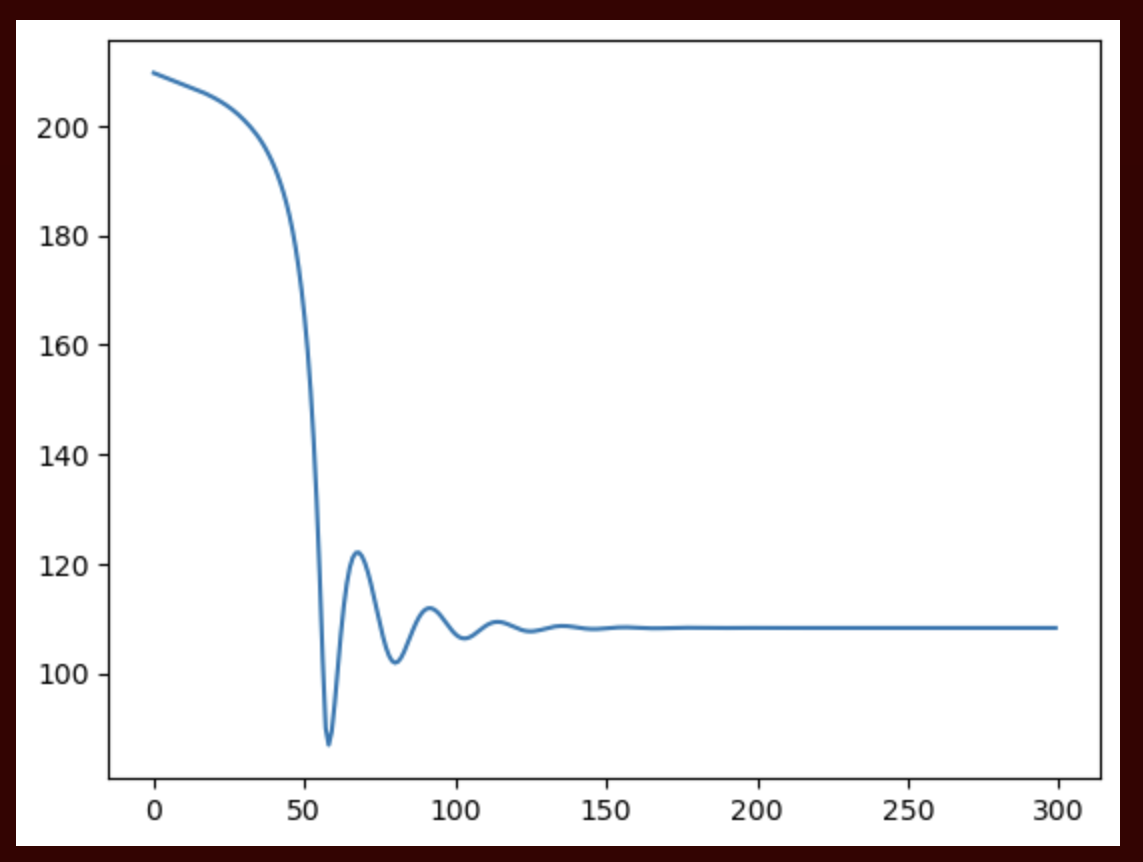

Now i will try with right around 54 odd epochs, to hopfully get small loss

however i found out what was happening was the epochs werent actually running, i had placed the zero grad in the wrong, place, but now the loss i right, its just predicting the mean

i think thats because there is not enough data to do anything BUT predict the mean to minizie loss

In [141]:
model.eval()
test = torch.tensor(data_x_norm[0],dtype=torch.float32)
with torch.no_grad():
    predictions = model(test)
print(predictions)
print(data_y[0])

tensor([7.3239e-06])
3.0


In [142]:
model.eval()
error = []
y_pred_list = []
with torch.no_grad():
    for x in data_x_norm:
        input = torch.tensor(x,dtype=torch.float32)
        y_pred = model(input)
        y_pred_list.append(y_pred[0])
        print(y_pred[0])

tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.3239e-06)
tensor(7.323

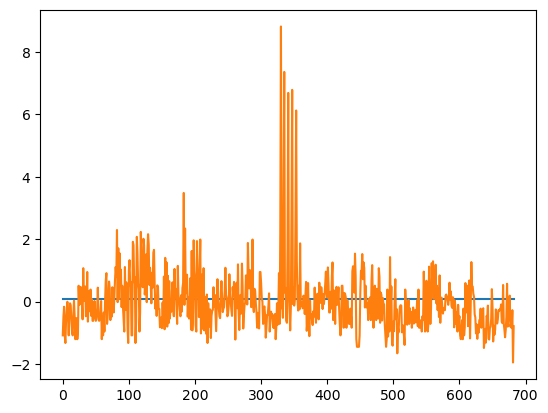

In [126]:
plt.plot(y_pred_list)
plt.plot(data_y_norm)

In [ ]:
class mlp_baseline(torch.nn.Module):
    def __init__(self,inputsize, depth, width):
        super().__init__()
        self.inp = torch.nn.Linear(inputsize, width)
        self.blocks = torch.nn.ModuleList([
            torch.nn.Sequential(
                torch.nn.Linear(width, width),
                torch.nn.tanh(),
            ) for _ in range(depth)
        ])
        self.out = torch.nn.Linear(width, 1)

    def forward(self, x):
        x = self.inp(x)
        for block in self.blocks:
            x = block(x)
        return self.out(x)


In [ ]:
crs_aea_epsg = CRS.from_epsg(5070) #albers eaqual area projection
transformer = Transformer.from_crs("EPSG:4326", crs_aea_epsg, always_xy=True) 

### Load in the station data

In [ ]:
statpath = "/home/exouser/code/labfetch/station_with_frp_2.csv"
df = pd.read_csv(statpath) 
station = df.to_xarray()
date_hour = station['Date Local'] + ' ' + station['Time Local']
# make new id that is unique per thing maybe?
new_id = station['County Code'].astype(str) + ' ' + station['Site Num'].astype(str) + ' ' + station['State Code'].astype(str) + ' ' + station['POC'].astype(str)
station = station.assign_coords({'lat':station['Latitude'],'long':station['Longitude'],'date_hour':date_hour,'new_id':new_id})

In [ ]:
np.unique(station.POC.values)

### Load in the weather data

In [ ]:
zarr_path = "/media/volume/firebackup/med_test/20250801_0000-20250831_2300_WF.zarr"

# 1. Dynamically find available fires to prevent ID KeyError
store = zarr.open_group(zarr_path, mode='r')
available_fires = list(store.group_keys())

if not available_fires:
    print("No fires found in the Zarr store!")
else:
    print(f"Fires available on disk: {available_fires}")
    
    # 2. Pick the first fire in the list (Change [0] to [1], etc. to view others)
    fire_id = available_fires[3] 

    # MUST use consolidated=False to read the appended stream correctly!
    ds = xr.open_zarr(zarr_path, group=fire_id , consolidated=False)  # group=fire_id 
    fire_name = ds.attrs.get('Fire_Name', '')
    ds.load()

### Making the date ranges

In [ ]:
date_r_compare,dates_str_compare,date_r_train,dates_str_train = training_date_ranges(start_date='2025-08-01 02:00',end_date='2025-08-31 21:00',hour_offset=1)

### Looping over the data example

In [ ]:
values,counts = np.unique(station.collective_frps.values,return_counts=True)

In [ ]:
station.collective_frps.values.shape

There is only 686 collective_frp values compared to the 960700 total values, meaning a total of 960014 iterations have no frp values

Problem statement, the index is not a identifier that is held across iterations of different time stamps, so a different identifier has to be made

In [ ]:
# NOTE: Times with with the 'compare' additition are the ones 1 hour in the future, ie the ones we use in the loss function and etc
# NOTE: This at the moment is hard coded in, this hour difference

# NOTE: We have a setting to skip over iterations that dont have a collective frp value, this is code in perhaps a slow way, 
# NOTE: As we just check to see if the frp value is nan at loading, so ill try and find a faster way.
skip_nans = True #this means as we iterate through all the values, we skip ones that nan, or have no collective frp value
for r_compare,str_compare,r_train,str_train in zip(date_r_compare,dates_str_compare,date_r_train,dates_str_train): #for each timestamp
    stations_current = station.sel(indexers={'date_hour':r_train}) #gets the current station info
    stations_future = station.sel(indexers={'date_hour':r_compare}) #gets the future station info

    weather_current = ds.sel(indexers={'time':str_train},method='nearest') #gets the current weather info
    #weather_future = ds.sel(indexers={'time':str_compare},method='nearest') #this would get the future, but we dont need it

    w_c_lon = weather_current.lon #gets the all the lat lon values for the weather in case we need it
    w_c_lat = weather_current.lat
    
    for i,stat in enumerate(stations_current['new_id']): #for each station by index of the current timestep
        site_id = stat.values
        try:
            stat_current = stations_current.sel(indexers={'new_id':site_id}) #get that specifc station by its index (current)
            stat_future = stations_future.sel(indexers={'new_id':site_id}) #(future)
        except KeyError:
            print("There was some sort of error when loading in these sites, skipping to the next one")
            continue
        col_frp = stat_current.collective_frps.values.flatten().item() #collective frp
        if math.isnan(col_frp): #skip if the frp collected is nan 
            col_frp = 0
            if skip_nans == True:
                continue
        
        dist = (weather_current.lat - stat_current.lat.values)**2 + (weather_current.lon - stat_current.long.values)**2
        min_idx = dist.argmin(dim=["y", "x"]) # Find the (y, x) index of the minimum distance  
        #this gets the weather info for the cell closest to the station
        weather_near_station = weather_current.isel(y=min_idx["y"].values, x=min_idx["x"].values)
        
        
        cur_pm = stat_current['Sample Measurement'].values.flatten().item() #gets the pm2.5 values, both current and future
        fut_pm = stat_future['Sample Measurement'].values.flatten().item()
        u10 = weather_near_station.u10.values.flatten().item() #wind component
        v10 = weather_near_station.v10.values.flatten().item()
        t2m = weather_near_station.t2m.values.flatten().item() #2 meter temp
        sp = weather_near_station.sp.values.flatten().item() #surface pressure
        d2m = weather_near_station.d2m.values.flatten().item() #dew point temp
        
        
            
        
        # TODO: REPLACE ALL NANS IN THE FRP WITH ZEROS

        # TODO: make it so it does a check that all values are valid,

        # TODO: make it check that the code is actually valid when indexing on the future one (it may not be) if so, skip it 
print("Finished looping over the entries")
        

# Station without any non valid collected frp values

In [ ]:
#station_only_frps = station.where(station.collective_frps !=np.nan,drop=True)
station_only_frps = station.dropna(dim="index", subset=['collective_frps'])
#station_only_frps = station.dropna(dim="collective_frps")
#ds_clean = ds.dropna(dim='time', subset=['your_variable'])

In [ ]:
station_only_frps.collective_frps.values.shape

In [ ]:
station_only_frps

In [ ]:

class mlp_baseline_2(torch.nn.Module):
    def __init__(self,inputsize, depth, width):
        super().__init__()
        self.inp = torch.nn.Linear(inputsize, width)
        self.blocks = torch.nn.ModuleList([
            torch.nn.Sequential(
                torch.nn.Linear(width, width),
                torch.nn.Tanh(),
            ) for _ in range(depth)
        ])
        self.out = torch.nn.Linear(width, 1)

    def forward(self, x):
        x = self.inp(x)
        for block in self.blocks:
            x = block(x)
        return self.out(x)

In [ ]:
model = mlp_baseline_2(inputsize=6,depth=3,width=6)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
L = torch.nn.MSELoss()


In [ ]:
# NOTE: Times with with the 'compare' additition are the ones 1 hour in the future, ie the ones we use in the loss function and etc
# NOTE: This at the moment is hard coded in, this hour difference
big_loss = []
y_pred_list = []
# NOTE: We have a setting to skip over iterations that dont have a collective frp value, this is code in perhaps a slow way, 
# NOTE: As we just check to see if the frp value is nan at loading, so ill try and find a faster way.
skip_nans = True #this means as we iterate through all the values, we skip ones that nan, or have no collective frp value
for r_compare,str_compare,r_train,str_train in zip(date_r_compare,dates_str_compare,date_r_train,dates_str_train): #for each timestamp
    try:
        stations_current = station_only_frps.sel(indexers={'date_hour':r_train}) #gets the current station info
        stations_future = station.sel(indexers={'date_hour':r_compare}) #gets the future station info
    except KeyError:
        #print("Nothing was found for this date, moving on")
        continue

    weather_current = ds.sel(indexers={'time':str_train},method='nearest') #gets the current weather info
    #weather_future = ds.sel(indexers={'time':str_compare},method='nearest') #this would get the future, but we dont need it

    w_c_lon = weather_current.lon #gets the all the lat lon values for the weather in case we need it
    w_c_lat = weather_current.lat
    #print(stations_current['new_id'].values)
    # NOTE: the issue is this is not always returning a full list, but instead sometimes just one value
    #need to make some test in case only one station is found

    #print(stations_current['new_id'].ndim)
    if stations_current['new_id'].ndim > 0:
        iterator = enumerate(stations_current['new_id'])    
        for i,stat in iterator: #for each station by index of the current timestep
            site_id = stat.values
            #print(site_id)
            try:
                stat_current = stations_current.sel(indexers={'new_id':site_id}) #get that specifc station by its index (current)
                stat_future = stations_future.sel(indexers={'new_id':site_id}) #(future)
            except KeyError:
                print("There was some sort of error when loading in these sites, skipping to the next one")
                continue
            col_frp = stat_current.collective_frps.values.flatten().item() #collective frp
            if math.isnan(col_frp): #skip if the frp collected is nan 
                col_frp = 0
                if skip_nans == True:
                    continue
            
            dist = (weather_current.lat - stat_current.lat.values)**2 + (weather_current.lon - stat_current.long.values)**2
            min_idx = dist.argmin(dim=["y", "x"]) # Find the (y, x) index of the minimum distance  
            #this gets the weather info for the cell closest to the station
            weather_near_station = weather_current.isel(y=min_idx["y"].values, x=min_idx["x"].values)
            
            
            cur_pm = stat_current['Sample Measurement'].values.flatten().item() #gets the pm2.5 values, both current and future
            frps = stat_current.collective_fprs.values.flatten().item() #gets the pm2.5 values, both current and future
            fut_pm = stat_future['Sample Measurement'].values.flatten().item()
            u10 = weather_near_station.u10.values.flatten().item() #wind component
            v10 = weather_near_station.v10.values.flatten().item()
            t2m = weather_near_station.t2m.values.flatten().item() #2 meter temp
            sp = weather_near_station.sp.values.flatten().item() #surface pressure
            d2m = weather_near_station.d2m.values.flatten().item() #dew point temp
            #print('completed gathering data')
            x = torch.tensor([cur_pm,u10,v10,t2m,sp,d2m])
            y = torch.tensor(fut_pm)
            mean = x.mean()
            std = x.std()
            standardized_x = (x - mean) / std
            optimizer.zero_grad()                       # Clear gradients

            y_pred = model(standardized_x)
            
            train_loss = L(y,y_pred[0])
            train_loss.backward() #accumulated gradients

            print(f"train_loss:{train_loss.item()}")
            print(f"y_pred:{y_pred}")
            big_loss.append(train_loss.item())
            y_pred_list.append(y_pred)
            optimizer.step()
    else:
        print('found a single station')
        stat_current = stations_current
        
        site_id = stations_current.new_id.values
        stat_future = stations_future.sel(indexers={'new_id':site_id})
        col_frp = stat_current.collective_frps.values.flatten().item() #collective frp
        if math.isnan(col_frp): #skip if the frp collected is nan 
            col_frp = 0
            if skip_nans == True:
                continue
        
        dist = (weather_current.lat - stat_current.lat.values)**2 + (weather_current.lon - stat_current.long.values)**2
        min_idx = dist.argmin(dim=["y", "x"]) # Find the (y, x) index of the minimum distance  
            #this gets the weather info for the cell closest to the station
        weather_near_station = weather_current.isel(y=min_idx["y"].values, x=min_idx["x"].values)
            
        #print(weather_near_station)
        cur_pm = stat_current['Sample Measurement'].values.flatten().item() #gets the pm2.5 values, both current and future
        #print(stat_future)
        fut_pm = stat_future['Sample Measurement'].values.flatten().item()
        u10 = weather_near_station.u10.values.flatten().item() #wind component
        v10 = weather_near_station.v10.values.flatten().item()
        t2m = weather_near_station.t2m.values.flatten().item() #2 meter temp
        sp = weather_near_station.sp.values.flatten().item() #surface pressure
        d2m = weather_near_station.d2m.values.flatten().item() #dew point temp
        #print('completed gathering data')
        #print([cur_pm,u10,v10,t2m,sp,d2m,fut_pm])
        
        x = torch.tensor([cur_pm,u10,v10,t2m,sp,d2m])
        y = torch.tensor(fut_pm)
        mean = x.mean()
        std = x.std()
        standardized_x = (x - mean) / std
        optimizer.zero_grad()                       # Clear gradients
        
        y_pred = model(standardized_x)
        train_loss = L(y,y_pred[0])
        train_loss.backward() #accumulated gradients
        print(f"train_loss:{train_loss.item()}")
        print(f"y_pred:{y_pred}")
        big_loss.append(train_loss.item())
        y_pred_list.append(y_pred)
        optimizer.step()
        
            
        
    
    
        
print("Finished looping over the entries")
        

In [ ]:
#station = station_only_frps
plt.plot(big_loss) #[600:]

do batching with the whole dataset, ie have it do the loss for the whole batch, then apply it
also run statistics on the orginal dataset for the pm2.5 levels and stuff
preload the data in 


In [ ]:
# NOTE: Times with with the 'compare' additition are the ones 1 hour in the future, ie the ones we use in the loss function and etc
# NOTE: This at the moment is hard coded in, this hour difference

# NOTE: We have a setting to skip over iterations that dont have a collective frp value, this is code in perhaps a slow way, 
# NOTE: As we just check to see if the frp value is nan at loading, so ill try and find a faster way.
skip_nans = True #this means as we iterate through all the values, we skip ones that nan, or have no collective frp value
for r_compare,str_compare,r_train,str_train in zip(date_r_compare,dates_str_compare,date_r_train,dates_str_train): #for each timestamp
    try:
        stations_current = station_only_frps.sel(indexers={'date_hour':r_train}) #gets the current station info
        stations_future = station.sel(indexers={'date_hour':r_compare}) #gets the future station info
    except KeyError:
        print("Nothing was found for this date, moving on")
        continue

    weather_current = ds.sel(indexers={'time':str_train},method='nearest') #gets the current weather info
    #weather_future = ds.sel(indexers={'time':str_compare},method='nearest') #this would get the future, but we dont need it

    w_c_lon = weather_current.lon #gets the all the lat lon values for the weather in case we need it
    w_c_lat = weather_current.lat
    #print(stations_current['new_id'].values)
    # NOTE: the issue is this is not always returning a full list, but instead sometimes just one value
    #need to make some test in case only one station is found

    print(stations_current['new_id'].ndim)
    if stations_current['new_id'].ndim > 0:
        iterator = enumerate(stations_current['new_id'])    
        for i,stat in enumerate(stations_current['new_id']): #for each station by index of the current timestep
            site_id = stat.values
            #print(site_id)
            try:
                stat_current = stations_current.sel(indexers={'new_id':site_id}) #get that specifc station by its index (current)
                stat_future = stations_future.sel(indexers={'new_id':site_id}) #(future)
            except KeyError:
                print("There was some sort of error when loading in these sites, skipping to the next one")
                continue
            col_frp = stat_current.collective_frps.values.flatten().item() #collective frp
            if math.isnan(col_frp): #skip if the frp collected is nan 
                col_frp = 0
                if skip_nans == True:
                    continue
            
            dist = (weather_current.lat - stat_current.lat.values)**2 + (weather_current.lon - stat_current.long.values)**2
            min_idx = dist.argmin(dim=["y", "x"]) # Find the (y, x) index of the minimum distance  
            #this gets the weather info for the cell closest to the station
            weather_near_station = weather_current.isel(y=min_idx["y"].values, x=min_idx["x"].values)
            
            
            cur_pm = stat_current['Sample Measurement'].values.flatten().item() #gets the pm2.5 values, both current and future
            fut_pm = stat_future['Sample Measurement'].values.flatten().item()
            u10 = weather_near_station.u10.values.flatten().item() #wind component
            v10 = weather_near_station.v10.values.flatten().item()
            t2m = weather_near_station.t2m.values.flatten().item() #2 meter temp
            sp = weather_near_station.sp.values.flatten().item() #surface pressure
            d2m = weather_near_station.d2m.values.flatten().item() #dew point temp
    else:
        print('found a single station')
        stat_current = stations_current
        print(stations_current)
        print(stations_future)
        
        print(site_id)
        #print(stat_future.ndim)
        if stat_future.collective_frps.ndim == 0:
            stat_future = stations_future
        else:
            site_id = stations_current.new_id.values
            stat_future = stations_future.sel(indexers={'new_id':site_id})
        col_frp = stat_current.collective_frps.values.flatten().item() #collective frp
        if math.isnan(col_frp): #skip if the frp collected is nan 
            col_frp = 0
            if skip_nans == True:
                continue
            
        dist = (weather_current.lat - stat_current.lat.values)**2 + (weather_current.lon - stat_current.long.values)**2
        min_idx = dist.argmin(dim=["y", "x"]) # Find the (y, x) index of the minimum distance  
            #this gets the weather info for the cell closest to the station
        weather_near_station = weather_current.isel(y=min_idx["y"].values, x=min_idx["x"].values)
            
            
        cur_pm = stat_current['Sample Measurement'].values.flatten().item() #gets the pm2.5 values, both current and future
        fut_pm = stat_future['Sample Measurement'].values.flatten().item()
        u10 = weather_near_station.u10.values.flatten().item() #wind component
        v10 = weather_near_station.v10.values.flatten().item()
        t2m = weather_near_station.t2m.values.flatten().item() #2 meter temp
        sp = weather_near_station.sp.values.flatten().item() #surface pressure
        d2m = weather_near_station.d2m.values.flatten().item() #dew point temp

        
            
        
        # TODO: REPLACE ALL NANS IN THE FRP WITH ZEROS

        # TODO: make it so it does a check that all values are valid,

        # TODO: make it check that the code is actually valid when indexing on the future one (it may not be) if so, skip it 
print("Finished looping over the entries")
        